# Is Diversification Worth It? — Analysis Notebook

**IS 445 · Fall 2026 · Final Project (Part 3.1)**  
**Authors:** Kunyang Jiang, Lucas Zhu, Oliver Lee, Yi-Hsun Kao

This reproducible notebook consolidates the relevant data checks and descriptive analyses from our earlier project work. The public-facing article is in `app.py`. The research question is whether government bonds offered a measure of protection in years when U.S. stocks posted losses.

## Data and scope

**Source:** [Jordà–Schularick–Taylor (JST) Macrohistory Database, Release 6](https://www.macrohistory.net/database/), produced by Òscar Jordà, Moritz Schularick, Alan M. Taylor, and collaborators at the MacroFinance & MacroHistory Lab. The original Excel snapshot is included unchanged at `data/JSTdatasetR6.xlsx` (CC BY-NC-SA 4.0; [terms](https://www.macrohistory.net/database/licence-terms/)).

We select `iso == "USA"` and annual observations from **1950–2020 inclusive**. Equity and government-bond **total returns** are taken from `eq_tr` and `bond_tr`, respectively. Both are **nominal fractional returns**: 0.10 is shown as 10%. We do not impute values or combine countries. The findings are descriptive, not investment recommendations or portfolio backtests.

In [1]:
from pathlib import Path
import hashlib
import pandas as pd
import matplotlib.pyplot as plt

file_path = Path("data/JSTdatasetR6.xlsx")
assert file_path.exists(), "Run this notebook from the repository root next to the data folder."

file_hash = hashlib.sha256(file_path.read_bytes()).hexdigest()
expected_hash = "c1bb91fe56ea50d4f27af5c0fc897d481e89ae38ce41eaecab62134c9354981d"
assert file_hash == expected_hash, "Original dataset does not match the project snapshot."

data = pd.read_excel(file_path, sheet_name="Sheet1", engine="openpyxl")
print("Raw data:", data.shape, "| countries:", data["iso"].nunique())

us = (
    data.loc[
        (data["iso"] == "USA") & data["year"].between(1950, 2020),
        ["year", "eq_tr", "bond_tr"],
    ]
    .sort_values("year")
    .reset_index(drop=True)
)
assert len(us) == 71 and us["year"].tolist() == list(range(1950, 2021))
assert us[["eq_tr", "bond_tr"]].notna().all().all()
assert not us["year"].duplicated().any()

us["Stocks"] = us["eq_tr"] * 100
us["Government bonds"] = us["bond_tr"] * 100
returns = us[["year", "Stocks", "Government bonds"]].copy()
print("Selected years:", returns["year"].min(), "to", returns["year"].max(), "| observations:", len(returns))
display(returns.head())

Raw data: (2718, 59) | countries: 18
Selected years: 1950 to 2020 | observations: 71


,year,Stocks,Government bonds
0,1950,28.295043,-0.073913
1,1951,25.670886,-3.725926
2,1952,17.257582,1.125197
3,1953,0.921659,3.600000
4,1954,47.039872,6.668254


## 1. Return and risk summary

We use arithmetic means, medians, and sample standard deviations of **annual nominal** percentage returns. The standard deviation is measured in *percentage points*. These values do not represent long-term compounded investment growth.

In [2]:
summary = pd.DataFrame({
    "Mean annual return (%)": returns[["Stocks", "Government bonds"]].mean(),
    "Median annual return (%)": returns[["Stocks", "Government bonds"]].median(),
    "Std. deviation (pp)": returns[["Stocks", "Government bonds"]].std(),
    "Minimum (%)": returns[["Stocks", "Government bonds"]].min(),
    "Maximum (%)": returns[["Stocks", "Government bonds"]].max(),
    "Negative years": (returns[["Stocks", "Government bonds"]] < 0).sum(),
})
display(summary.round(2))
print("Annual-return correlation:", round(returns["Stocks"].corr(returns["Government bonds"]), 3))

,Mean annual return (%),Median annual return (%),Std. deviation (pp),Minimum (%),Maximum (%),Negative years
Stocks,12.38,14.21,16.22,-38.75,47.04,14
Government bonds,6.12,3.60,10.54,-15.22,36.34,24


Annual-return correlation: -0.049


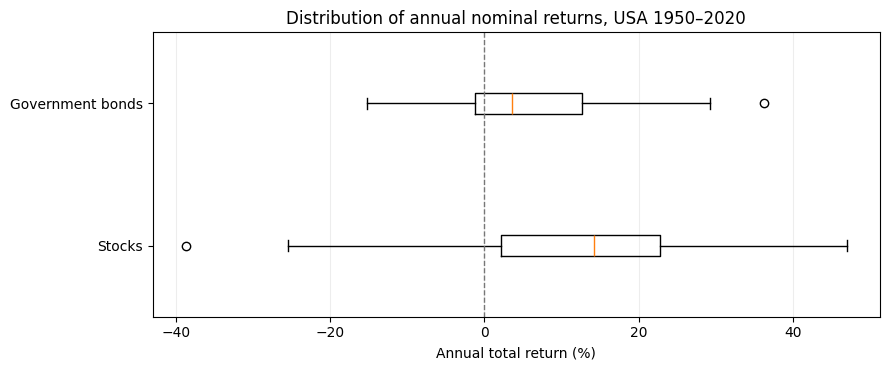

In [3]:
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.boxplot(
    [returns["Stocks"], returns["Government bonds"]],
    vert=False,
    tick_labels=["Stocks", "Government bonds"],
)
ax.axvline(0, color="#777777", linewidth=1, linestyle="--")
ax.set_title("Distribution of annual nominal returns, USA 1950–2020")
ax.set_xlabel("Annual total return (%)")
ax.grid(axis="x", alpha=0.22)
plt.tight_layout()
plt.show()

## 2. Did bonds gain in stock-loss years?

We flag years when stock returns were strictly below 0%, then count the corresponding government-bond outcomes. A bond gain in a stock-loss year is evidence of different annual behavior, but does not by itself prove an optimal portfolio mix.

Years with stock losses: 14
Stock-loss years with positive bonds: 11
Years both assets lost money: 3
Both-negative years: [1969, 1973, 1981]


,year,Stocks,Government bonds
7,1957,-9.30,7.75
10,1960,-0.52,13.14
12,1962,-9.72,7.67
16,1966,-8.21,4.40
19,1969,-11.48,-5.54
23,1973,-16.46,-3.83
24,1974,-25.44,2.55
27,1977,-5.93,1.41
31,1981,-2.30,-0.07
40,1990,-2.23,5.43


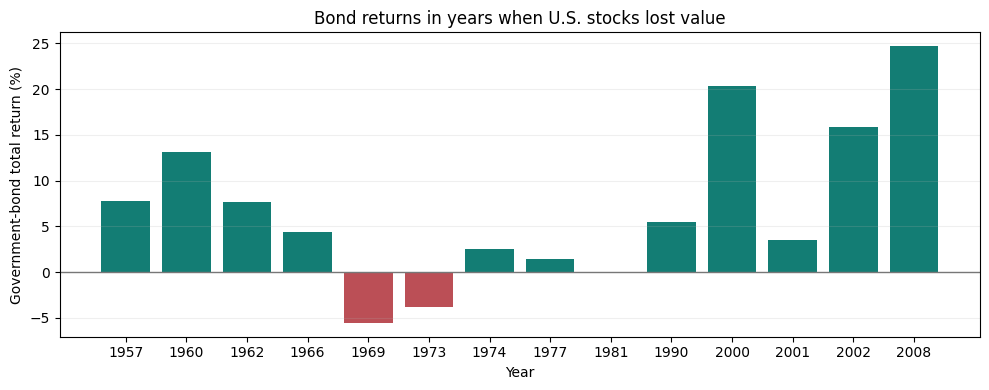

In [4]:
stock_down = returns.loc[returns["Stocks"] < 0].copy()
bond_up = stock_down["Government bonds"] > 0
both_down = stock_down["Government bonds"] < 0
print("Years with stock losses:", len(stock_down))
print("Stock-loss years with positive bonds:", int(bond_up.sum()))
print("Years both assets lost money:", int(both_down.sum()))
print("Both-negative years:", stock_down.loc[both_down, "year"].tolist())
display(stock_down.round(2))

fig, ax = plt.subplots(figsize=(10, 4))
colors = ["#137D74" if value > 0 else "#BB4F56" for value in stock_down["Government bonds"]]
ax.bar(stock_down["year"].astype(str), stock_down["Government bonds"], color=colors)
ax.axhline(0, color="#777777", linewidth=1)
ax.set_title("Bond returns in years when U.S. stocks lost value")
ax.set_xlabel("Year")
ax.set_ylabel("Government-bond total return (%)")
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

## 3. Interpretive limits and reproducibility

The **1950–2020** U.S. sample has **71 complete annual records**, not 71 independent market experiments. Historical means and correlations describe past experience; they do not predict future results. Values are **nominal**, so purchasing-power changes are not subtracted. Annual data also cannot show within-year drawdowns. These series are historically constructed stock and government-bond returns, not ETF prices. No hypothetical 60/40 portfolio, rebalancing plan, fees, or taxes have been modeled here.

**Data license:** [CC BY-NC-SA 4.0](https://www.macrohistory.net/database/licence-terms/); original XLSX remains unchanged and charts are team-created adaptations for noncommercial academic use.

**Suggested citations:** Jordà, Schularick & Taylor (2017), *Macrofinancial History and the New Business Cycle Facts*; Jordà, Knoll, Kuvshinov, Schularick & Taylor (2019), *The Rate of Return on Everything, 1870–2015*.